# Lgr6 & Notch1 perturbations

Fitting STD model to Notch1-Cre and Lgr6-Cre clonal lineage tracing data (ED Fig 9-10).


## Running fitting: 
### Finding best fits
To find best fits with simulated annealing run: [FitSTD.py](../../modelling/FitSTD.py):
```bash
#Comment out the model use
mode=1 #Use 2D
#mode=0 #Use 0D

parallel --max-procs 15 python3.12 FitSTD.py {1} 1 $mode notchM 1000 0.0 1.0 -1 0 -1 ::: {-015..-001} &
parallel --max-procs 15 python3.12 FitSTD.py {1} 1 $mode notchM 1000 1.0 1.0 -1 0 -1 ::: {-030..-016} &
parallel --max-procs 15 python3.12 FitSTD.py {1} 1 $mode notchF 1000 0.0 1.0 -1 0 -1 ::: {-015..-001} &
parallel --max-procs 15 python3.12 FitSTD.py {1} 1 $mode notchF 1000 1.0 1.0 -1 0 -1 ::: {-030..-016} &
parallel --max-procs 15 python3.12 FitSTD.py {1} 1 $mode lgr6M 1000 0.0 1.0 -1 0 -1 ::: {-015..-001} &
parallel --max-procs 15 python3.12 FitSTD.py {1} 1 $mode lgr6M 1000 1.0 1.0 -1 0 -1 ::: {-030..-016} &
parallel --max-procs 15 python3.12 FitSTD.py {1} 1 $mode lgr6F 1000 0.0 1.0 -1 0 -1 ::: {-015..-001} &
parallel --max-procs 15 python3.12 FitSTD.py {1} 1 $mode lgr6F 1000 1.0 1.0 -1 0 -1 ::: {-030..-016} &

```

At the end to combine files run:
```bash
#Analyse simulations
python3.12 FitSTD.py -2000 1 0 notchF 1000 &
python3.12 FitSTD.py -2000 1 0 notchM 1000 &
python3.12 FitSTD.py -2000 1 0 lgr6F 1000 &
python3.12 FitSTD.py -2000 1 0 lgr6M 1000 &
```


### Estimating parameter uncertainty with grid search+bootstrapping
To estimate parameter uncertainty run: [FitSTD.py](../../modelling/FitSTD.py):

```bash
#Run bootstrapping
parallel --max-procs 30 python3.12 FitSTD.py {1} 1 $mode notchF 1000 0.0 1.0 -1 0 -1 ::: {0..15000} &
parallel --max-procs 30 python3.12 FitSTD.py {1} 1 $mode notchM 1000 0.0 1.0 -1 0 -1 ::: {0..15000} &
parallel --max-procs 30 python3.12 FitSTD.py {1} 1 $mode lgr6F 1000 0.0 1.0 -1 0 -1 ::: {0..15000} &
parallel --max-procs 30 python3.12 FitSTD.py {1} 1 $mode lgr6M 1000 0.0 1.0 -1 0 -1 ::: {0..15000} &



#Analyse simulations
python3.12 FitSTD.py -1000 1 0 notchF 1000 &
python3.12 FitSTD.py -1000 1 0 notchM 1000 &
python3.12 FitSTD.py -1000 1 0 lgr6F 1000 &
python3.12 FitSTD.py -1000 1 0 lgr6M 1000 &
```

In [ ]:
#Imports
import numpy as np
import matplotlib.pyplot as plt
import sys
import pickle

sys.path.append("../../analysis/")
sys.path.append("../../sim/")
sys.path.append("../../fit/")
sys.path.append("../../plot/")


from tissue import *
import tissplot as tplt
import matplotlib.path as mplPath
import analysis
import datasets as ds 
import tiss_optimize as topt
import sim_model
import os
import custom_metrics as cmet


def get_bootstrap_ci(bootstrap_samples, axis=0, confidence=0.95):
    """
    Calculate confidence intervals from bootstrap samples along a specified axis.
    
    Parameters:
    -----------
    bootstrap_samples : array-like
        3D array of bootstrap samples where:
        - First dimension is the number of bootstrap samples
        - Second and third dimensions are your original 2D data shape
    axis : int, default=0
        The axis of the original 2D data along which to calculate CIs
        0 = calculate CI for each column
        1 = calculate CI for each row
    confidence : float, default=0.95
        Confidence level (0 to 1)
        
    Returns:
    --------
    tuple
        (lower_bounds, upper_bounds, means)
        Each is an array corresponding to the CIs and means along the specified axis
    """
    # Convert input to numpy array if it isn't already
    samples = np.asarray(bootstrap_samples)
    
    # Calculate alpha for confidence interval
    alpha = (1 - confidence) / 2
    
    # Calculate percentiles and mean along the bootstrap samples dimension
    # Add 1 to axis because original axis 0/1 is now 1/2 due to bootstrap dimension
    lower_bounds = np.nanpercentile(samples, alpha * 100, axis=0)
    upper_bounds = np.nanpercentile(samples, (1 - alpha) * 100, axis=0)
    means = np.mean(samples, axis=0)
    
    # If axis=0 (columns), we want stats for each column of original data
    # If axis=1 (rows), we want stats for each row of original data
    if axis == 0:
        return lower_bounds, upper_bounds, means
    elif axis == 1:
        return (lower_bounds.T, upper_bounds.T, means.T)
    else:
        raise ValueError("Axis must be 0 or 1")



#Metrics
ksdists  = {'dist': ['S2like.basalCS', 'S2like.supraCS'], 'dist_metric': 'ksd', 'name': 'ksd_b_sb'}
k1dists  = {'dist': ['S2like.basalCS'], 'dist_metric': 'ksd', 'name': 'ksd_bas'}

ll_dist_STD = {'dist': ['Slike.fullbasalCS', 'Slike.fullsupraCS',
                    'Tlike.fullbasalCS', 'Tlike.fullsupraCS',
                    'Dlike.fullbasalCS', 'Dlike.fullsupraCS', 
                    'S2like.xfrac'], 
                    'dist_metric': 'lLL', 'name': 'll_STD'}

ll_dist_SPD = {'dist': ['S4like.fullbasalCS', 'S4like.fullsupraCS',
                    'CPlike.fullbasalCS', 'CPlike.fullsupraCS',
                    'Dlike.fullbasalCS', 'Dlike.fullsupraCS'], 
                    'dist_metric': 'lLL', 'name': 'll_SPD'}
T0 = 50
mets = [ll_dist_SPD, ll_dist_STD, ksdists, k1dists] 
compute_kwargs = {'Dlike': {'containsBasal': False}}
toCalculate = ['basalCS', 'S4like.basalCS', 'S4like.supraCS', 'CPlike.basalCS', 'CPlike.supraCS', 'Dlike.basalCS', 'Dlike.supraCS',
               'Tlike.basalCS', 'Tlike.supraCS', 'Slike.basalCS', 'Slike.supraCS', 'S2like.basalCS', 'S2like.supraCS',
               'T3like.basalCS', 'T3like.supraCS', 'S2like.xfrac', 'Slike.xfrac', 'Tlike.xfrac', 'Dlike.xfrac',
               'S4like.lcd', 'T3like.lcd', 'CPlike.lcd', 'Dlike.lcd', 'Slike.lcd', 'Tlike.lcd', 'S2like.lcd',
               'S4like.pers', 'T3like.pers', 'CPlike.pers', 'Dlike.pers', 'Slike.pers', 'Tlike.pers', 'S2like.pers',
               'supraCS']


from matplotlib import rcParams
# Set global font size for all axes
rcParams['axes.labelsize'] = 12
rcParams['xtick.labelsize'] = 10
rcParams['ytick.labelsize'] = 10
rcParams['legend.fontsize'] = 7.5
rcParams['font.size'] = 10  # General font size
rcParams['text.usetex'] = False
rcParams['font.family'] = 'sans-serif'
rcParams['font.sans-serif'] = ['Arial']
rcParams['svg.fonttype'] = 'none'
rcParams['lines.markersize']  = 3
rcParams['lines.linewidth']  = 1.5



In [ ]:
'''  
    Getting best fits & parameter uncertainties from bootstrapping
'''

def boot_stats_STD(s0, met, best_fit):
    boot_stats = s0.boot_stats(met).T

    boot_stats['rhoS'] = best_fit['rhoS']
    boot_stats['tscale'] = -boot_stats[met + ':tscale']
    boot_stats['tau'] = 100
    boot_stats['CVd_S'] = best_fit['CVd_S']
    boot_stats['corrST'] = best_fit['corrST']
    boot_stats['corrTD'] = best_fit['corrTD']

    boot_stats['mu'] = ((boot_stats['q']-2)*boot_stats['rhoS']*boot_stats['tau'] + boot_stats['tau']*(1-boot_stats['rhoS']))/(boot_stats['rhoS']*(3-boot_stats['q']))#/boot_stats['tau']*boot_stats['tscale']
    boot_stats['rhoT1'] = boot_stats['tau']/(boot_stats['tau'] + ((3 - boot_stats['q'])*boot_stats['mu'] + (2 - boot_stats['q'])*boot_stats['tau']))
    boot_stats['rhoT2'] = boot_stats['tau']*(1-boot_stats['q'])/(boot_stats['tau'] + ((3 - boot_stats['q'])*boot_stats['mu'] + (2 - boot_stats['q'])*boot_stats['tau']))
    boot_stats['rhoD'] = boot_stats['mu']*(3-boot_stats['q'])/(boot_stats['tau'] + ((3 - boot_stats['q'])*boot_stats['mu'] + (2 - boot_stats['q'])*boot_stats['tau']))
    boot_stats['mu1'] = boot_stats['mu']
    boot_stats['mu'] = ((boot_stats['q']-2)*boot_stats['rhoS']*boot_stats['tau'] + boot_stats['tau']*(1-boot_stats['rhoS']))/(boot_stats['rhoS']*(3-boot_stats['q']))/boot_stats['tau']*boot_stats['tscale']
    boot_stats['rhoT'] = boot_stats['rhoT1'] + boot_stats['rhoT2']
    boot_stats = boot_stats[['tscale', 'mu', 'shed', 'r', 'q', 'rhoS', 'rhoT1', 'rhoT2', 'rhoD', 'rhoT', 'CVd_S', 'CVd_D', 'corrST', 'corrTD', 'corrDD', 'corrSS']]
    return boot_stats

ncells = 1000
tau = 100.0
cST = 1.0
cTD = 0.0
cvS = 1.0
L = 20
hilln = 0.0
ncores = 1

T = -30



cols = {'M': 'r', 'F': 'b', 'castre': 'purple', 'notchF': 'b', 'notchM': 'r', 'lgr6F': 'b', 'lgr6M': 'r'}
sexname = {'M': 'M', 'F': 'F', 'castre': 'cM', 'notchF': 'nF', 'notchM': 'nM', 'lgr6F': 'lF', 'lgr6M': 'lM'}

sim_datasets = {}
exp_datasets = {}
best_fits = {}

all_boots_sex = {}


for sex in ['notchF', 'notchM', 'lgr6F', 'lgr6M']:
    if sex == 'M':
        exp_file = '../../experiment/homeo/data_ctr_M.pkl'
        rhoS = 0.3
        cv_sb = 1.0
        q = 0.55
        r = 0.15
    elif sex == 'F':
        exp_file = '../../experiment/homeo/data_ctr_F.pkl'
        rhoS = 0.275
        cv_sb = 0.1   
        q = 1.0 #0.75
        r = 0.125
    elif sex == 'castre':
        exp_file = '../../experiment/castre/data_castre.pkl'
        rhoS = 0.275
        cv_sb = 1.0    
        q = 0.75
        r = 0.1
    elif sex == 'notchF':
        exp_file = '../../experiment/notch/data_Notch1_F.pkl'
        rhoS = 0.26
        cv_sb = np.arange(0.1, 1.1, 0.15) #[1.0]
        q = 1.0
        r = 0.2
        tscale_inc_times = np.arange(1,5)
        T = -15
    elif sex == 'notchM':
        exp_file = '../../experiment/notch/data_Notch1_M.pkl'
        rhoS = 0.34
        cv_sb = np.arange(0.1, 1.1, 0.15) #[1.0]
        q = 1
        r = 0.2
        T = -15
        tscale_inc_times = np.arange(1,5)
    elif sex == 'lgr6M':
        exp_file = '../../experiment/lgr6/data_Lgr6_M.pkl'
        rhoS = 0.26 #0.26
        cv_sb = np.arange(0.1, 1.1, 0.15) #[1.0]
        q = 1.0
        r = 0.2
        T = -15
        tscale_inc_times = np.arange(1,5)
    elif sex == 'lgr6F':
        exp_file = '../../experiment/lgr6/data_Lgr6_F.pkl'
        rhoS = 0.26
        cv_sb = np.arange(0.1, 1.1, 0.15) #[1.0]
        q = 1.0
        r = 0.2
        T = -15
        tscale_inc_times = np.arange(1,5)

    for mode in [0]:
        print(ncores, mode, sex)

        if mode == 0:
            savefolder = 'modelling/ST2D_0D_finale_boots/'
            savefolder1 = 'modelling/ST2D_0D_finale/'
            nseeds = 1
            s0 = topt.sim_anneal(sim_model.ST2D_0D, { 'r': [r],
                                                'CVd_D': [1.0],
                                                'corrSS': [0.0],
                                                'corrDD': [0.0],
                                                'q': [q]},
                                params = {'tau': tau, 'refractT': -1, 'corrTT': -1.0,
                                        'CVd_T': -1.0, 'corrTD': cTD, 'rhoS': rhoS,
                                        'CVd_S': cvS, 'corrST':  cST}, simtype = 'h',
                            exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                            compute_kwargs = compute_kwargs, toCalculate = toCalculate,
                        move_seed = np.abs(0),  use_linear = ['r', 'rhoS', 'q', 'CVd_S', 'CVd_D', 'corrST', 'corrDD', 'corrSS'],
                        move_sizes =     {'r': 0.025, 'rhoS':  0.025, 'q': 0.025, 'CVd_S':  0.05, 'CVd_D':  0.05, 'corrST':  0.05, 'corrDD':  0.05, 'corrSS':  0.05},
                        free_param_min = {'r': 0.00, 'rhoS':   0.1, 'q':  0.0, 'CVd_S':  0.0, 'CVd_D':  0.0, 'corrST':  0.0, 'corrDD':  0.0, 'corrSS':  0.0},
                        free_param_max = {'r': 1.00, 'rhoS':   1.0, 'q':  1.01, 'CVd_S': 1.04, 'CVd_D': 1.04, 'corrST': 1.04, 'corrDD': 1.04, 'corrSS': 1.04})
        elif mode == 1:
            savefolder = 'modelling/ST2D_2D_finale_boots/'
            savefolder1 = 'modelling/ST2D_2D_finale/'
            nseeds = ncores
            s0 = topt.sim_anneal(sim_model.ST2D_size, { 'r': [r],
                                                'CVd_D': [1.0],
                                                'corrSS': [1.0],
                                                'corrDD': [1.0],
                                                'q': [q]},
                                params = {'tau': tau, 'refractT': -1, 'corrTT': -1.0,
                                        'CVd_T': -1.0, 'corrTD': cTD, 'rhoS': rhoS,
                                        'CVd_S': cvS, 'corrST':  cST, 
                                        'L': L, 'hilln': hilln}, simtype = 'h',
                            exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                            compute_kwargs = compute_kwargs, toCalculate = toCalculate,
                        move_seed = np.abs(0),  use_linear = ['r', 'rhoS', 'q', 'CVd_S', 'CVd_D', 'corrST', 'corrDD', 'corrSS'],
                        move_sizes =     {'r': 0.025, 'rhoS':  0.025, 'q': 0.025, 'CVd_S':  0.05, 'CVd_D':  0.05, 'corrST':  0.05, 'corrDD':  0.05, 'corrSS':  0.05},
                        free_param_min = {'r': 0.00, 'rhoS':   0.1, 'q':  0.0, 'CVd_S':  0.0, 'CVd_D':  0.0, 'corrST':  0.0, 'corrDD':  0.0, 'corrSS':  0.0},
                free_param_max = {'r': 1.00, 'rhoS':   1.0, 'q':  1.01, 'CVd_S': 1.04, 'CVd_D': 1.04, 'corrST': 1.04, 'corrDD': 1.04, 'corrSS': 1.04})
    
        
        s0.load_existing(tsteps = T, ncells = ncells, savefolder = savefolder1, 
                        tscalevals = -np.arange(4,15,0.05), shedvals = -np.arange(0.45, 1.05, 0.05), 
                        postopt_params = {'sbas_cv': [cv_sb]})
        for met in ['ll_SPD']: # 'll_STD', 'ksd_bas', 'ksd_b_sb'
            best_fits[(savefolder1, sex, met)] = s0.best_fit(met)
            #print(s0.sim_save_name(T, ncells, int(best_fits[(savefolder1, sex, met)].name), 0))
            #print(best_fits[(savefolder, sex, met)])        
        
        s0.load_existing(tsteps = T, ncells = ncells, savefolder = savefolder, 
                        tscalevals = -np.arange(4,15,0.05), shedvals = -np.arange(0.45, 1.05, 0.05), 
                        postopt_params = {'sbas_cv': [cv_sb]})        
        
        #s0.searchspace = s0.searchspace[s0.searchspace['corrTD'] == 0.0]

        for met in ['ll_SPD']: # 'll_STD', 'ksd_bas', 'ksd_b_sb'
            print(sex, s0.searchspace[met].min(), met)
            best_fits[(savefolder, sex, met)] = s0.best_fit(met)
            print(s0.sim_save_name(T, ncells, int(best_fits[(savefolder1, sex, met)].name), 0))
            print('tscale = ', best_fits[(savefolder1, sex, met)]['tscale'])
            boot_stats = boot_stats_STD(s0, met, best_fits[(savefolder, sex, met)])
            #print(s0.boot_stats(met).to_markdown())        
            #print(boot_stats.to_string(float_format=lambda x: f"{x:.3f}"))
            print(boot_stats.to_markdown())

            b = s0.searchspace['ll_SPD:boot_costs'].values
            nboots = len(b[0])
            all_boots = np.array([b1 if np.ndim(b1) > 0 else np.ones(nboots)*1e10 for b1 in b])

            all_boots_sex[sex] = all_boots

1 0 notchF
notchF 1694.4665913467497 ll_SPD
hrun_ST2D_0D_t_-15_n_1000_CVd_D_0.8_CVd_S_0.6_CVd_T_-1.0_corrDD_0.7_corrSS_0.5_corrST_1.0_corrTD_1.0_corrTT_-1.0_q_0.775_r_0.2_refractT_-1.0_rhoS_0.26_tau_100.0_seed_0.pkl
tscale =  -4.3
|          |    tscale |         mu |     shed |         r |         q |   rhoS |   rhoT1 |    rhoT2 |     rhoD |     rhoT |   CVd_S |   CVd_D |   corrST |   corrTD |   corrDD |   corrSS |
|:---------|----------:|-----------:|---------:|----------:|----------:|-------:|--------:|---------:|---------:|---------:|--------:|--------:|---------:|---------:|---------:|---------:|
| Best     |  4.3      |  3.13302   | 3.44     | 0.2       | 0.775     |   0.26 |    0.26 | 0.0585   | 0.4215   | 0.3185   |     0.6 |     0.8 |        1 |        1 | 0.7      |  0.5     |
| Mean     |  4.119    |  2.94715   | 3.294    | 0.1725    | 0.758     |   0.26 |    0.26 | 0.06292  | 0.41708  | 0.32292  |     0.6 |     1   |        1 |        1 | 0.594    |  0.3825  |
| Median   | 

In [9]:
s0.searchspace[s0.searchspace['ll_SPD:tscale'] < -5]

,index,r,corrSS,corrDD,q,tau,refractT,corrTT,CVd_T,corrTD,...,ll_SPD:sweeps,ksd_b_sb:sweeps,ll_STD,ll_STD:shed,ll_STD:tscale,ksd_bas,ksd_bas:shed,ksd_bas:tscale,τ/r,shed
195,195,0.500,0.00,0.4,0.400,100.0,-1.0,-1.0,-1.0,0.0,...,None,None,NaN,NaN,NaN,NaN,NaN,NaN,200.000000,3.3475
345,345,0.500,0.00,0.7,0.400,100.0,-1.0,-1.0,-1.0,0.0,...,None,None,NaN,NaN,NaN,NaN,NaN,NaN,200.000000,3.9000
346,346,0.500,0.25,0.7,0.400,100.0,-1.0,-1.0,-1.0,0.0,...,None,None,NaN,NaN,NaN,NaN,NaN,NaN,200.000000,4.0875
497,497,0.500,0.50,1.0,0.400,100.0,-1.0,-1.0,-1.0,0.0,...,None,None,NaN,NaN,NaN,NaN,NaN,NaN,200.000000,3.8850
499,499,0.500,1.00,1.0,0.400,100.0,-1.0,-1.0,-1.0,0.0,...,None,None,NaN,NaN,NaN,NaN,NaN,NaN,200.000000,3.6075
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16066,6940,0.425,0.50,0.9,0.700,100.0,-1.0,-1.0,-1.0,0.0,...,None,None,NaN,NaN,NaN,NaN,NaN,NaN,235.294118,4.1200
17589,6860,0.475,0.50,0.1,0.975,100.0,-1.0,-1.0,-1.0,0.0,...,None,None,NaN,NaN,NaN,NaN,NaN,NaN,210.526316,4.0800
18507,6885,0.400,0.50,0.8,0.850,100.0,-1.0,-1.0,-1.0,0.0,...,None,None,NaN,NaN,NaN,NaN,NaN,NaN,250.000000,4.3600
18530,6908,0.425,0.50,0.8,0.875,100.0,-1.0,-1.0,-1.0,0.0,...,None,None,NaN,NaN,NaN,NaN,NaN,NaN,235.294118,4.0800


In [ ]:
'''  
    Simulated annealing
'''

ncells = 1000
tau = 100.0
cST = 1.0
cTD = 0.0
cvS = 0.5
L = 20
hilln = 0.0
ncores = 1
ncells1 = 5000

T = -30

mathfolder = 'math:/store/BIOPHYS/jth42/glassy-tissue-turnover/S-T-D-model/ForPaper/'


cols = {'M': 'r', 'F': 'b', 'castre': 'purple', 'notchF': 'b', 'notchM': 'r', 'lgr6F': 'b', 'lgr6M': 'r'}
sexname = {'M': 'M', 'F': 'F', 'castre': 'cM', 'notchF': 'nF', 'notchM': 'nM', 'lgr6F': 'lF', 'lgr6M': 'lM'}

sim_datasets = {}
sim_datasets_full = {}
exp_datasets = {}
best_fits = {}


for sex in ['notchF', 'notchM', 'lgr6F', 'lgr6M']:
    if sex == 'M':
        exp_file = '../../experiment/homeo/data_ctr_M.pkl'
        rhoS = 0.3
        cv_sb = 1.0
        q = 0.55
        r = 0.15
    elif sex == 'F':
        exp_file = '../../experiment/homeo/data_ctr_F.pkl'
        rhoS = 0.275
        cv_sb = 0.1   
        q = 1.0 #0.75
        r = 0.125
    elif sex == 'castre':
        exp_file = '../../experiment/castre/data_castre.pkl'
        rhoS = 0.275
        cv_sb = 1.0    
        q = 0.75
        r = 0.1
    elif sex == 'notchF':
        exp_file = '../../experiment/notch/data_Notch1_F.pkl'
        rhoS = 0.26
        cv_sb = np.arange(0.1, 1.1, 0.15) #[1.0]
        q = 1.0
        r = 0.2
        tscale_inc_times = np.arange(1,5)
        T = -15
    elif sex == 'notchM':
        exp_file = '../../experiment/notch/data_Notch1_M.pkl'
        rhoS = 0.34
        cv_sb = np.arange(0.1, 1.1, 0.15) #[1.0]
        q = 1
        r = 0.2
        T = -15
        tscale_inc_times = np.arange(1,5)
    elif sex == 'lgr6M':
        exp_file = '../../experiment/lgr6/data_Lgr6_M.pkl'
        rhoS = 0.26 #0.26
        cv_sb = np.arange(0.1, 1.1, 0.15) #[1.0]
        q = 1.0
        r = 0.2
        T = -15
        tscale_inc_times = np.arange(1,5)
    elif sex == 'lgr6F':
        exp_file = '../../experiment/lgr6/data_Lgr6_F.pkl'
        rhoS = 0.26
        cv_sb = np.arange(0.1, 1.1, 0.15) #[1.0]
        q = 1.0
        r = 0.2
        T = -15
        tscale_inc_times = np.arange(1,5)

    for mode in [0]:
        print(ncores, mode, sex)

        if mode == 0:
            savefolder = 'modelling/ST2D_0D_finale/'
            nseeds = 1
            s0 = topt.sim_anneal(sim_model.ST2D_0D, { 'r': [r],
                                                'CVd_D': [1.0],
                                                'corrSS': [0.0],
                                                'corrDD': [0.0],
                                                'q': [q]},
                                params = {'tau': tau, 'refractT': -1, 'corrTT': -1.0,
                                        'CVd_T': -1.0, 'corrTD': cTD, 'rhoS': rhoS,
                                        'CVd_S': cvS, 'corrST':  cST}, simtype = 'h',
                            exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                            compute_kwargs = compute_kwargs, toCalculate = toCalculate,
                        move_seed = np.abs(0),  use_linear = ['r', 'rhoS', 'q', 'CVd_S', 'CVd_D', 'corrST', 'corrDD', 'corrSS'],
                        move_sizes =     {'r': 0.025, 'rhoS':  0.025, 'q': 0.025, 'CVd_S':  0.05, 'CVd_D':  0.05, 'corrST':  0.05, 'corrDD':  0.05, 'corrSS':  0.05},
                        free_param_min = {'r': 0.00, 'rhoS':   0.1, 'q':  0.0, 'CVd_S':  0.0, 'CVd_D':  0.0, 'corrST':  0.0, 'corrDD':  0.0, 'corrSS':  0.0},
                        free_param_max = {'r': 1.00, 'rhoS':   1.0, 'q':  1.01, 'CVd_S': 1.04, 'CVd_D': 1.04, 'corrST': 1.04, 'corrDD': 1.04, 'corrSS': 1.04})
        elif mode == 1:
            savefolder = 'modelling/ST2D_2D_finale/'
            nseeds = ncores
            s0 = topt.sim_anneal(sim_model.ST2D_size, { 'r': [r],
                                                'CVd_D': [1.0],
                                                'corrSS': [1.0],
                                                'corrDD': [1.0],
                                                'q': [q]},
                                params = {'tau': tau, 'refractT': -1, 'corrTT': -1.0,
                                        'CVd_T': -1.0, 'corrTD': cTD, 'rhoS': rhoS,
                                        'CVd_S': cvS, 'corrST':  cST, 
                                        'L': L, 'hilln': hilln}, simtype = 'h',
                            exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                            compute_kwargs = compute_kwargs, toCalculate = toCalculate,
                        move_seed = np.abs(0),  use_linear = ['r', 'rhoS', 'q', 'CVd_S', 'CVd_D', 'corrST', 'corrDD', 'corrSS'],
                        move_sizes =     {'r': 0.025, 'rhoS':  0.025, 'q': 0.025, 'CVd_S':  0.05, 'CVd_D':  0.05, 'corrST':  0.05, 'corrDD':  0.05, 'corrSS':  0.05},
                        free_param_min = {'r': 0.00, 'rhoS':   0.1, 'q':  0.0, 'CVd_S':  0.0, 'CVd_D':  0.0, 'corrST':  0.0, 'corrDD':  0.0, 'corrSS':  0.0},
                free_param_max = {'r': 1.00, 'rhoS':   1.0, 'q':  1.01, 'CVd_S': 1.04, 'CVd_D': 1.04, 'corrST': 1.04, 'corrDD': 1.04, 'corrSS': 1.04})
    
        s0.load_existing(tsteps = T, ncells = ncells, savefolder = savefolder, 
                        tscalevals = -np.arange(4,15,0.05), shedvals = -np.arange(0.45, 0.95, 0.05), 
                        postopt_params = {'sbas_cv': [cv_sb]})
        
        
        for met in ['ll_SPD']: # 'll_STD', 'ksd_bas', 'ksd_b_sb'
            print(sex, s0.searchspace[met].min(), met)
            best_fits[(savefolder, sex, met)] = s0.best_fit(met)
            print(s0.sim_save_name(T, ncells, int(best_fits[(savefolder, sex, met)].name), 0))
            
            if s0.searchspace[met].min() >= 1e10:
                print('Missing fit')
                continue
            
            #continue
            sim_data = s0.get_best_fit(met, T, ncells1, savefolder = savefolder, nseeds = 1, 
                                       save_results = True, skip = 5, print_fit = False,
                                        norun = False)
            exp_data = s0.exp_data


            sim_datasets_full[sex] = sim_data
            sdt = sim_data.data_time_crop()
            sim_datasets[sex] = sdt
            exp_datasets[sex] = exp_data


1 0 notchF
notchF 1694.4665913467497 ll_SPD
hrun_ST2D_0D_t_-15_n_1000_CVd_D_0.8_CVd_S_0.6_CVd_T_-1.0_corrDD_0.7_corrSS_0.5_corrST_1.0_corrTD_1.0_corrTT_-1.0_q_0.775_r_0.2_refractT_-1.0_rhoS_0.26_tau_100.0_seed_0.pkl
tscale: -4.3
τ range: 1.7333333333333334 to 80.0
Starting sim with 4999 cells at Mon Aug 17 22:43:18 2026
Ending sim with 5027 cells at Mon Aug 17 22:43:38 2026
Resetting time and division times
Starting sim with 5027 cells at Mon Aug 17 22:43:41 2026
Ending sim with 4744 cells at Mon Aug 17 22:44:31 2026
shed: -0.8 refract: 0.0 cv: 0.4
1 0 notchM
notchM 1576.9839922189383 ll_SPD
hrun_ST2D_0D_t_-15_n_1000_CVd_D_0.85_CVd_S_0.55_CVd_T_-1.0_corrDD_0.6_corrSS_0.5_corrST_1.0_corrTD_0.0_corrTT_-1.0_q_1.0_r_0.15_refractT_-1.0_rhoS_0.34_tau_100.0_seed_0.pkl
tscale: -4.5
τ range: 1.7333333333333334 to 80.0
shed: -0.75 refract: 0.0 cv: 0.55
1 0 lgr6F
lgr6F 949.2548475335899 ll_SPD
hrun_ST2D_0D_t_-15_n_1000_CVd_D_0.95_CVd_S_0.55_CVd_T_-1.0_corrDD_0.6_corrSS_0.5_corrST_1.0_corrTD_0.0_c

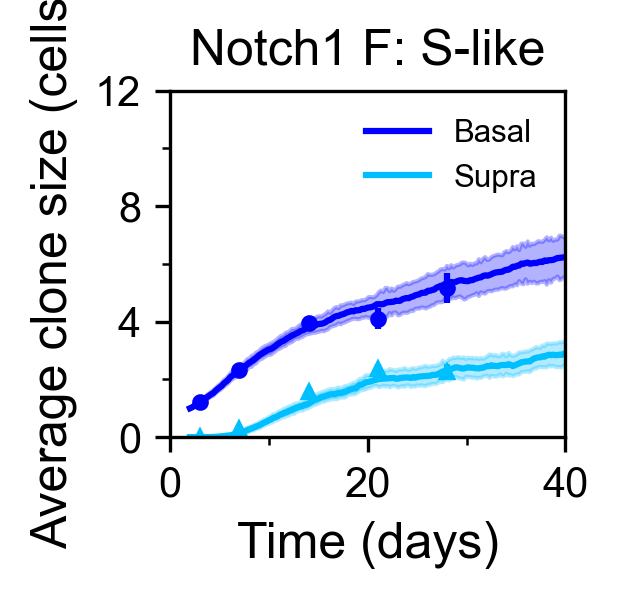

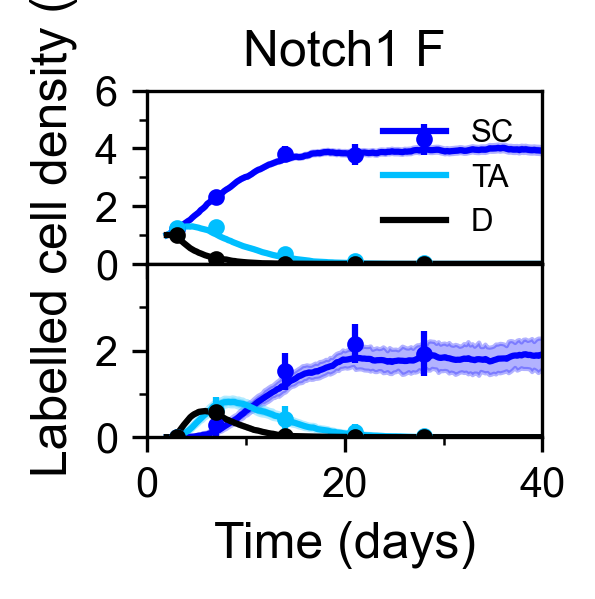

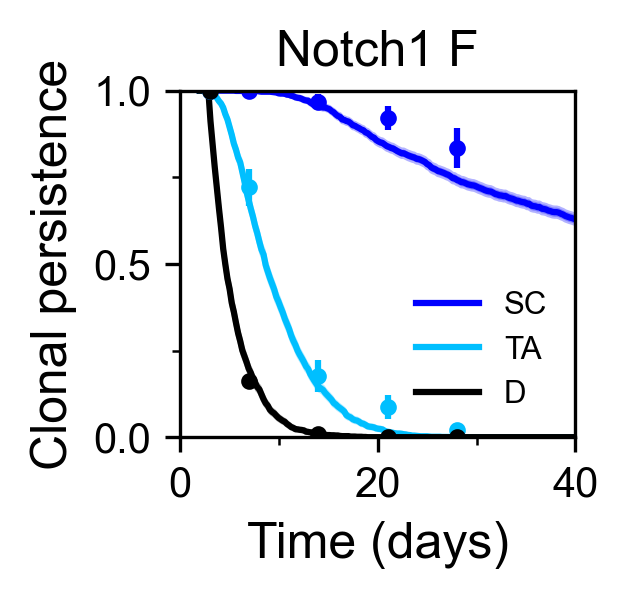

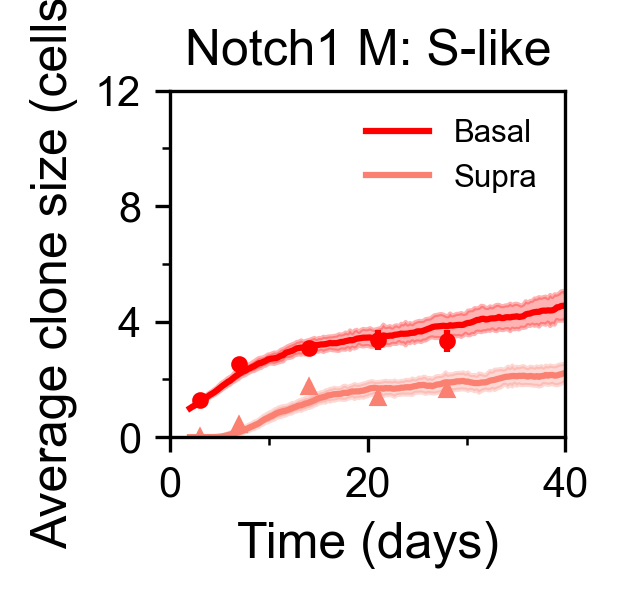

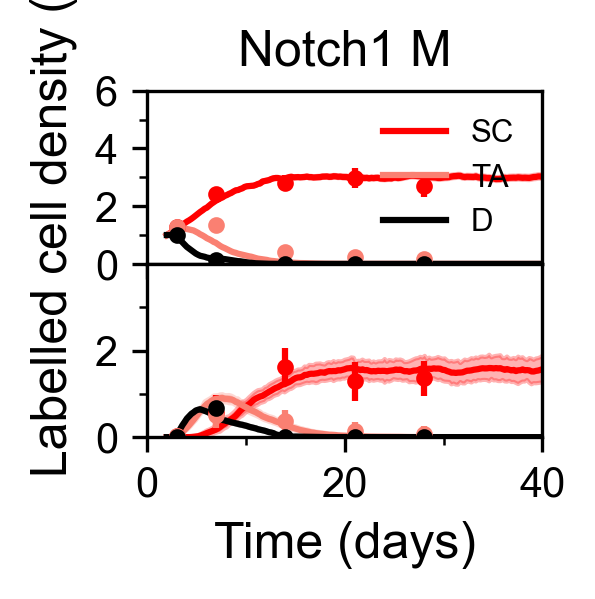

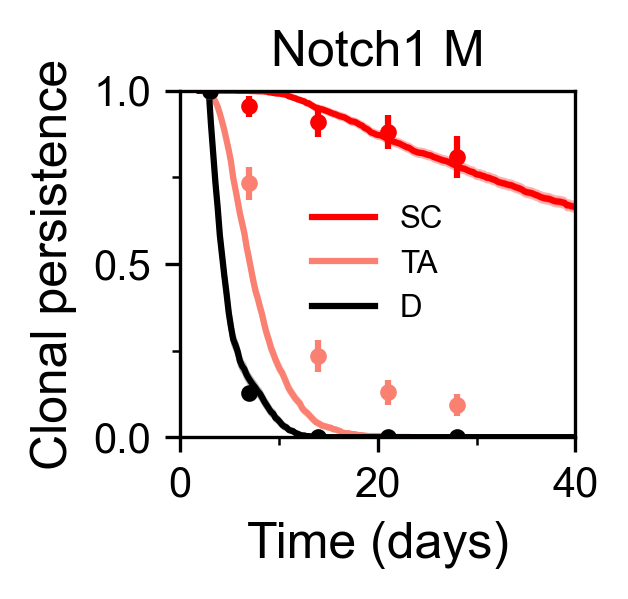

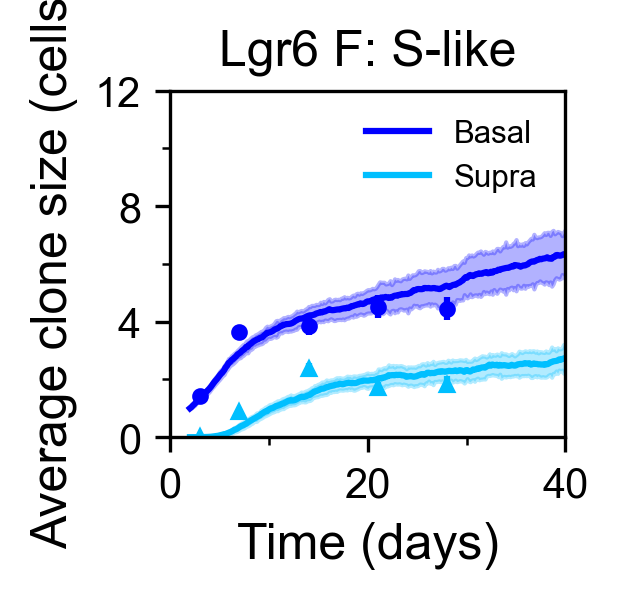

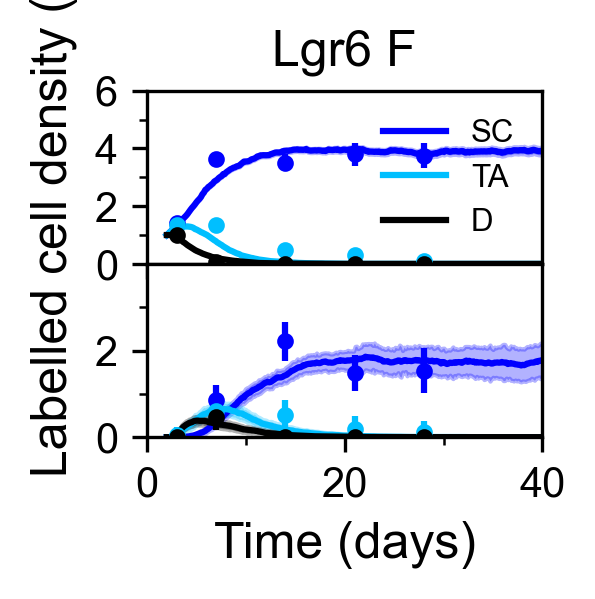

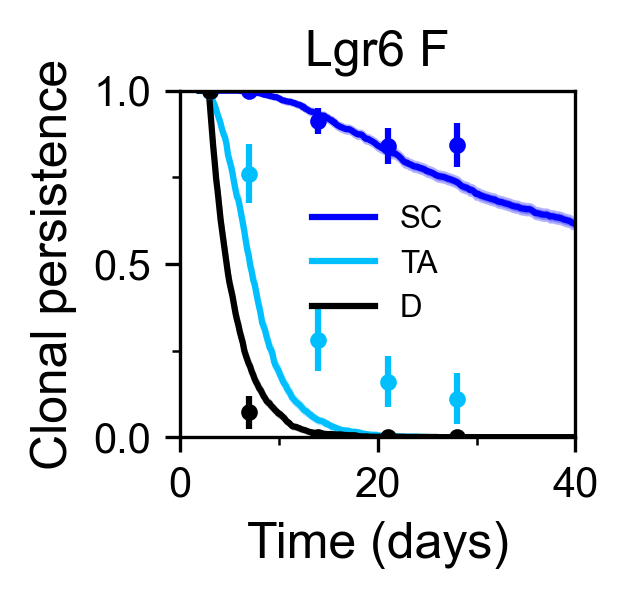

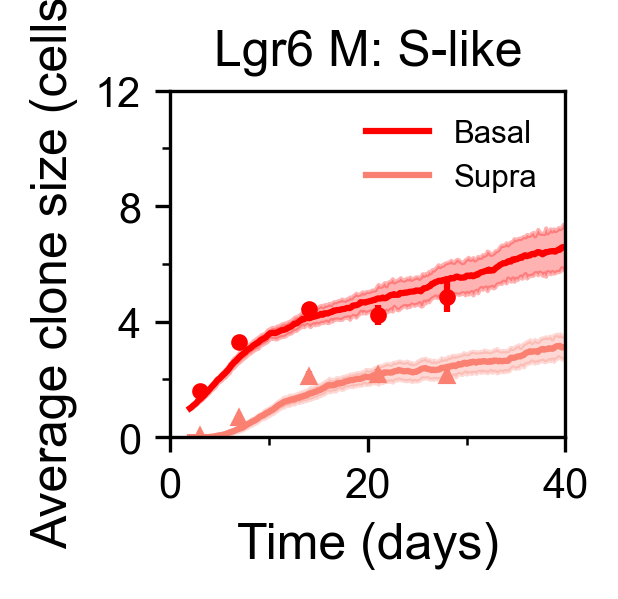

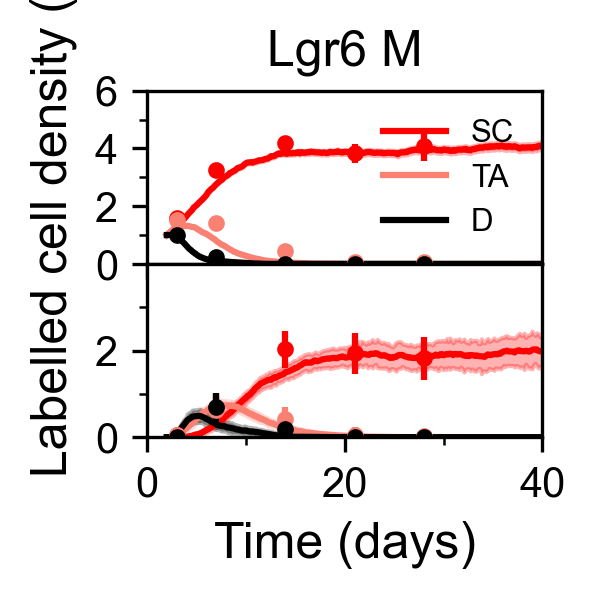

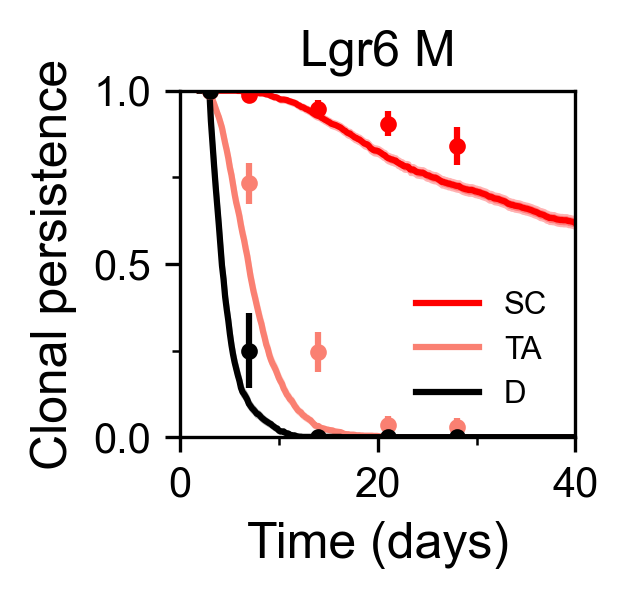

In [11]:
#K14
figfolder = 'SFig6_Notch_Lgr6/'

fullsex = {'M': 'Male', 'F': 'Female', 'castre': 'Castrated male', 'notchF': 'Notch1 F', 'notchM': 'Notch1 M', 'lgr6F': 'Lgr6 F', 'lgr6M': 'Lgr6 M'}

for sex in  ['notchF', 'notchM', 'lgr6F', 'lgr6M']:
    exp_data = exp_datasets[sex]
    sim_data = sim_datasets_full[sex]
    sdt = sim_datasets[sex]

    sec_cols = {'M': 'salmon', 'F': 'deepskyblue', 'castre': 'violet', 'notchF': 'deepskyblue', 'notchM': 'salmon', 'lgr6F': 'deepskyblue', 'lgr6M': 'salmon'}


    plt.figure(figsize = (1.7,1.5), dpi = 300)  
    ds.plot_quantity('S4like.basalCS', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'Basal', color = cols[sex], xfmt = 'o', sfmt = '-')
    ds.plot_quantity('S4like.supraCS', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'Average clone size (cells)', plot_seeded = False, bootSEs = True, prelabel = 'Supra', color = sec_cols[sex], xfmt = '^', sfmt = '-')
    plt.xlim([0,40])
    plt.ylim([0,12])
    plt.yticks(np.arange(0, 13, 4))
    plt.yticks(np.arange(0, 13, 2), minor = True)
    plt.xticks(np.arange(0, 41, 20))
    plt.xticks(np.arange(0, 41, 10), minor = True)
    plt.legend(frameon = False)
    plt.title(fullsex[sex] + ': S-like')
    plt.savefig(f'Figures/{figfolder}{sex}_av_size.pdf', dpi = 300)     
    plt.show() 


    plt.figure(figsize = (1.7,1.5), dpi = 300)
    plt.subplot(2,1,1)
    ds.plot_quantity('S4like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'SC', color =  cols[sex])

    ds.plot_quantity('CPlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'TA', color = sec_cols[sex])           
    ds.plot_quantity('Dlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'Labelled cell density (cells)', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
    plt.ylim([0,6])
    plt.yticks(np.arange(0, 7, 2))
    plt.yticks(np.arange(0, 7, 1), minor = True)
    plt.legend(frameon = False)
    plt.title(fullsex[sex])
    plt.xlim([0,40])
    plt.xticks([0,10,20, 30], minor = True)
    plt.xticks([0,20], minor = False, alpha = 0.0)
    #plt.xticks([])
    plt.xlabel('  ')

    #plt.show()
    plt.subplot(2,1,2)
    ds.plot_quantity('S4like.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'SC', color =  cols[sex], nolegend = True)
    ds.plot_quantity('CPlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'TA', color = sec_cols[sex], nolegend = True)           
    ds.plot_quantity('Dlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'Supra labelled cell density (cells)', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k', nolegend = True)    
    plt.ylim([0,4])
    plt.yticks(np.arange(0, 4, 2))
    plt.yticks(np.arange(0, 4, 1), minor = True)
    plt.xlim([0,40])
    plt.xticks(np.arange(0, 41, 20))
    plt.xticks(np.arange(0, 41, 10), minor = True)
    plt.ylabel('')
    plt.subplots_adjust(wspace=0, hspace=0)
    plt.tight_layout()
    plt.savefig(f'Figures/{figfolder}{sex}_lcd.pdf', dpi = 300)     
    plt.show()             



    plt.figure(figsize = (1.7,1.5), dpi = 300)
    ds.plot_quantity('S4like.pers', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'Persistence', plot_seeded = False, bootSEs = True, prelabel = 'SC', color =  cols[sex])
    ds.plot_quantity('CPlike.pers', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'Persistence', plot_seeded = False, bootSEs = True, prelabel = 'TA', color = sec_cols[sex])
    ds.plot_quantity('Dlike.pers', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'Clonal persistence', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
    #plt.title(fullsex[sex])
    plt.xlim([0,40])
    plt.ylim([0,1])
    plt.yticks(np.arange(0, 1.1, 0.5))
    plt.yticks(np.arange(0, 1.1, 0.25), minor = True)
    plt.xticks(np.arange(0, 41, 20))
    plt.xticks(np.arange(0, 41, 10), minor = True)
    plt.legend(frameon = False)
    plt.title(fullsex[sex])
    plt.savefig(f'Figures/{figfolder}{sex}_pers.pdf', dpi = 300)     
    plt.show() 

In [ ]:
import clones 
load_object = ds.load_object

K14_new_exp_datasets = {}
s0.load_exp_data('../../experiment/homeo/data_ctr_M.pkl', 'ctr', '', 2.0, compute_kwargs, np.inf)
K14_new_exp_datasets['M'] = s0.exp_data
s0.load_exp_data('../../experiment/homeo/data_ctr_F.pkl', 'ctr', '', 2.0, compute_kwargs, np.inf)
K14_new_exp_datasets['F'] = s0.exp_data

Lgr6_exp_datasets = {}
s0.load_exp_data('../../experiment/lgr6/data_Lgr6_M.pkl', 'ctr', '', 2.0, compute_kwargs, np.inf)
Lgr6_exp_datasets['M'] = s0.exp_data
s0.load_exp_data('../../experiment/lgr6/data_Lgr6_F.pkl', 'ctr', '', 2.0, compute_kwargs, np.inf)   
Lgr6_exp_datasets['F'] = s0.exp_data

Notch_exp_datasets = {}
s0.load_exp_data('../../experiment/notch/data_Notch1_M.pkl', 'ctr', '', 2.0, compute_kwargs, np.inf)
Notch_exp_datasets['M'] = s0.exp_data
s0.load_exp_data('../../experiment/notch/data_Notch1_F.pkl', 'ctr', '', 2.0, compute_kwargs, np.inf)
Notch_exp_datasets['F'] = s0.exp_data

Already cropped
Already cropped
Already cropped
Already cropped
Already cropped
Already cropped
Already cropped
Already cropped


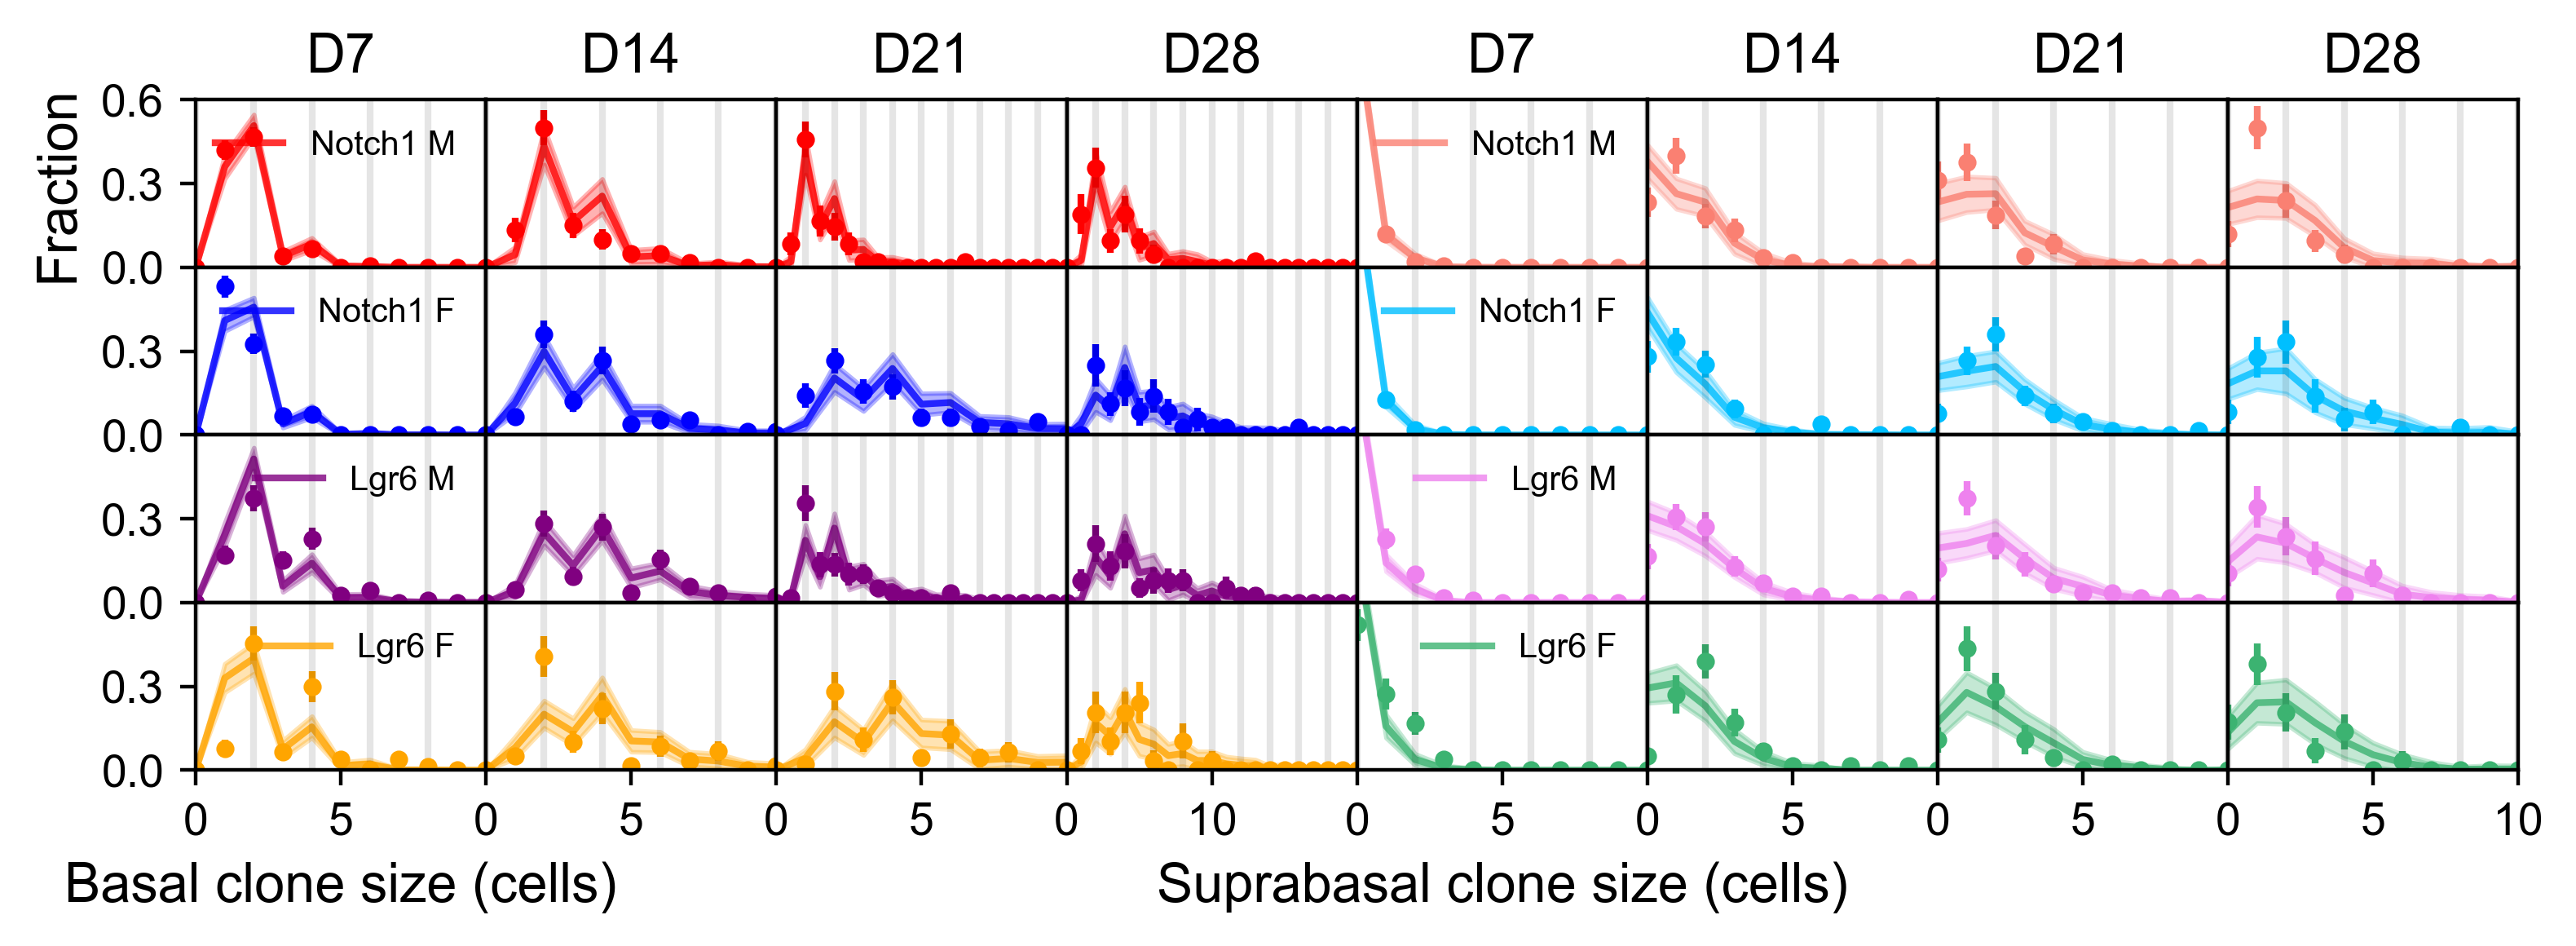

In [31]:
fullsex = {'M': 'Male', 'F': 'Female', 'castre': 'Castrated male', 'notchF': 'Notch1 F', 'notchM': 'Notch1 M', 'lgr6F': 'Lgr6 F', 'lgr6M': 'Lgr6 M'}
cols = {'M': 'r', 'F': 'b', 'castre': 'purple', 'notchF': 'b', 'notchM': 'r', 'lgr6F': 'orange', 'lgr6M': 'purple'}
sec_cols = {'M': 'salmon', 'F': 'deepskyblue', 'castre': 'violet', 'notchF': 'deepskyblue', 'notchM': 'salmon', 'lgr6F': 'mediumseagreen', 'lgr6M': 'violet'}

figfolder = 'SFig6_Notch_Lgr6/'

ys = 0.75
iw = 1.0

sex = 'notchM'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

axs = ds.plot_dist('basalCS', sdt, exp_data, subtimes = np.arange(1,5), maxbin = 25, cdf = False, 
                   xlabel= 'Basal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = iw, ymax = 0.6, xmax = [10, 10, 20, 20],
                ylabel = 'Fraction', nolegend = True, yscale = ys, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2), nrows = 4)    

sex = 'notchF'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]
axs = ds.plot_dist('basalCS', sdt, exp_data, subtimes = np.arange(1,5), maxbin = 25, cdf = False, 
                   xlabel= 'Basal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = iw, ymax = 0.6, xmax = [10, 10, 10, 20],
                ylabel = 'Clone fraction', nolegend = True, yscale = ys, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2), subplot_axs = axs, x0 = 8, nrows  = 4)  



sex = 'notchM'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

axs = ds.plot_dist('supraCS', sdt, exp_data, subtimes = np.arange(1,5), maxbin = 25, cdf = False, 
                   xlabel= 'Supra clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{sec_cols[sex]}',
                ncols=8, im_width = iw, ymax = 0.6, xmax = [10, 10, 10, 10], subplot_axs = axs,
                ylabel = 'Clone frequency', nolegend = True, yscale = ys, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2), x0 = 4, nrows = 4)    

sex = 'notchF'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]
axs = ds.plot_dist('supraCS', sdt, exp_data, subtimes = np.arange(1,5), maxbin = 25, cdf = False, 
                   xlabel= 'Supra clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{sec_cols[sex]}',
                ncols=8, im_width = iw, ymax = 0.6, xmax = [10, 10, 10, 10],
                ylabel = 'Clone fraction', nolegend = True, yscale = ys, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2), subplot_axs = axs, x0 = 12, nrows = 4)  



sex = 'lgr6M'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

axs = ds.plot_dist('basalCS', sdt, exp_data, subtimes = np.arange(1,5), maxbin = 25, cdf = False, 
                   xlabel= 'Basal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}', subplot_axs = axs,
                ncols=8, im_width = iw, ymax = 0.6, xmax = [10, 10, 20, 20],
                ylabel = 'Clone frequency', nolegend = True, yscale = ys, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2), nrows = 4, x0 = 16)    

sex = 'lgr6F'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]
axs = ds.plot_dist('basalCS', sdt, exp_data, subtimes = np.arange(1,5), maxbin = 25, cdf = False, 
                   xlabel= 'Basal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = iw, ymax = 0.6, xmax = [10, 10, 10, 20],
                ylabel = 'Clone fraction', nolegend = True, yscale = ys, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2), subplot_axs = axs, x0 = 24, nrows  = 4)  



sex = 'lgr6M'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

axs = ds.plot_dist('supraCS', sdt, exp_data, subtimes = np.arange(1,5), maxbin = 25, cdf = False, 
                   xlabel= 'Supra clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{sec_cols[sex]}',
                ncols=8, im_width = iw, ymax = 0.6, xmax = [10, 10, 10, 10], subplot_axs = axs,
                ylabel = 'Clone frequency', nolegend = True, yscale = ys, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2), x0 = 20, nrows = 4)    

sex = 'lgr6F'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]
axs = ds.plot_dist('supraCS', sdt, exp_data, subtimes = np.arange(1,5), maxbin = 25, cdf = False, 
                   xlabel= 'Supra clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{sec_cols[sex]}',
                ncols=8, im_width = iw, ymax = 0.6, xmax = [10, 10, 10, 10],
                ylabel = 'Clone fraction', nolegend = True, yscale = ys, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2), subplot_axs = axs, x0 = 28, nrows = 4)  


#axs[1,0].set_xlabel('Basal clone size (cells)')
axs[3,0].set_xlabel('Basal clone size (cells)')
axs[3,4].set_xlabel('Suprabasal clone size (cells)')
axs[0,0].legend(loc='upper right', frameon=False)
axs[1,0].legend(loc='upper right', frameon=False)
axs[2,0].legend(loc='upper right', frameon=False)
axs[3,0].legend(loc='upper right', frameon=False)
axs[0,4].legend(loc='upper right', frameon=False)
axs[1,4].legend(loc='upper right', frameon=False)
axs[2,4].legend(loc='upper right', frameon=False)
axs[3,4].legend(loc='upper right', frameon=False)
plt.savefig(f'Figures/{figfolder}/Fig_all_pdfs_combined.pdf', dpi = 300)   

# Combined data 

Accounting for labelling bias between populations

Repairing basal CS mistakes for [66]
[[[1 0 5 6 8]
  [0 1 0 2 4]]]
Repairing basal CS mistakes for [66]
[[[1 0 5 6 8]
  [0 1 0 2 4]]]
Repairing basal CS mistakes for [66]
[[[1 0 5 6 8]
  [0 1 0 2 4]]]


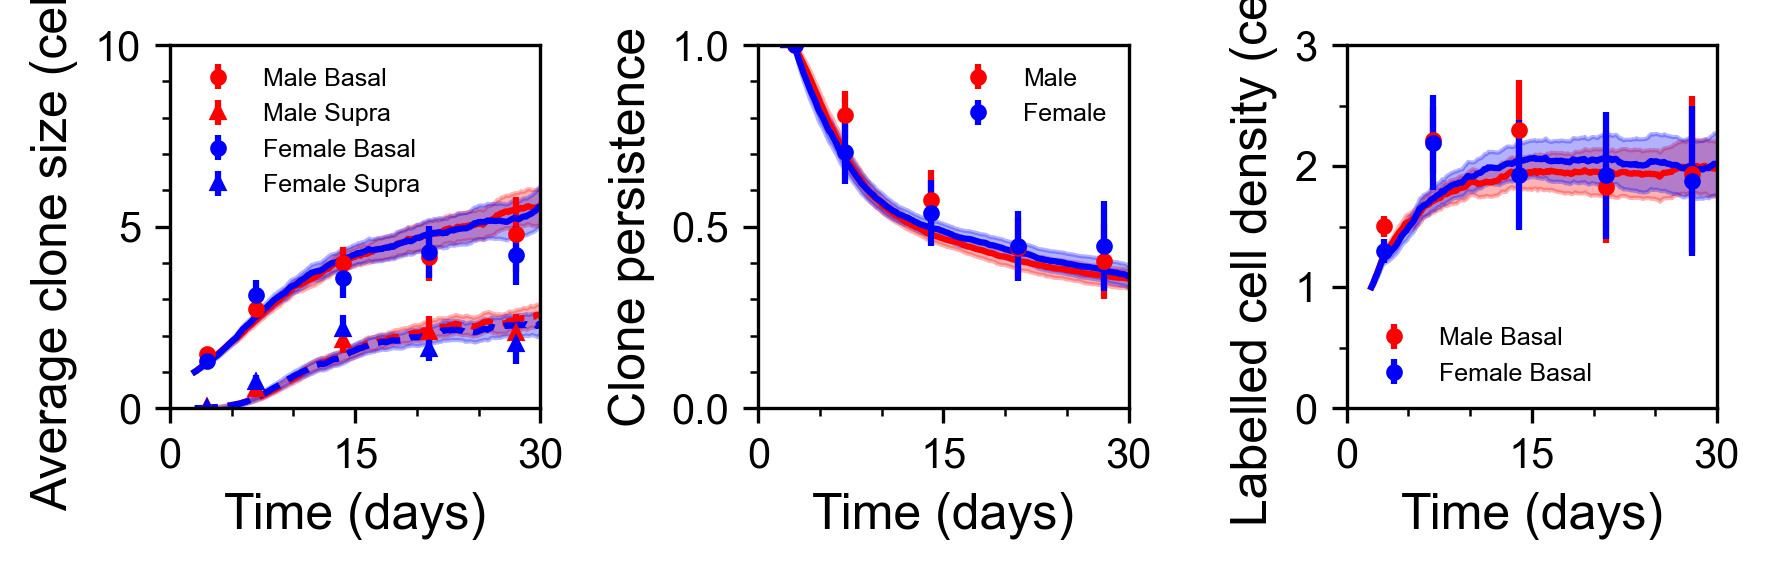

Repairing basal CS mistakes for [254]
[[[1 2 0 0 2]
  [0 0 2 2 0]]]
Repairing basal CS mistakes for [246]
[[[0 2 0 0 0]
  [1 0 0 0 0]]]
Repairing basal CS mistakes for [254]
[[[1 2 0 0 2]
  [0 0 2 2 0]]]
Repairing basal CS mistakes for [246]
[[[0 2 0 0 0]
  [1 0 0 0 0]]]
Repairing basal CS mistakes for [254]
[[[1 2 0 0 2]
  [0 0 2 2 0]]]
Repairing basal CS mistakes for [246]
[[[0 2 0 0 0]
  [1 0 0 0 0]]]


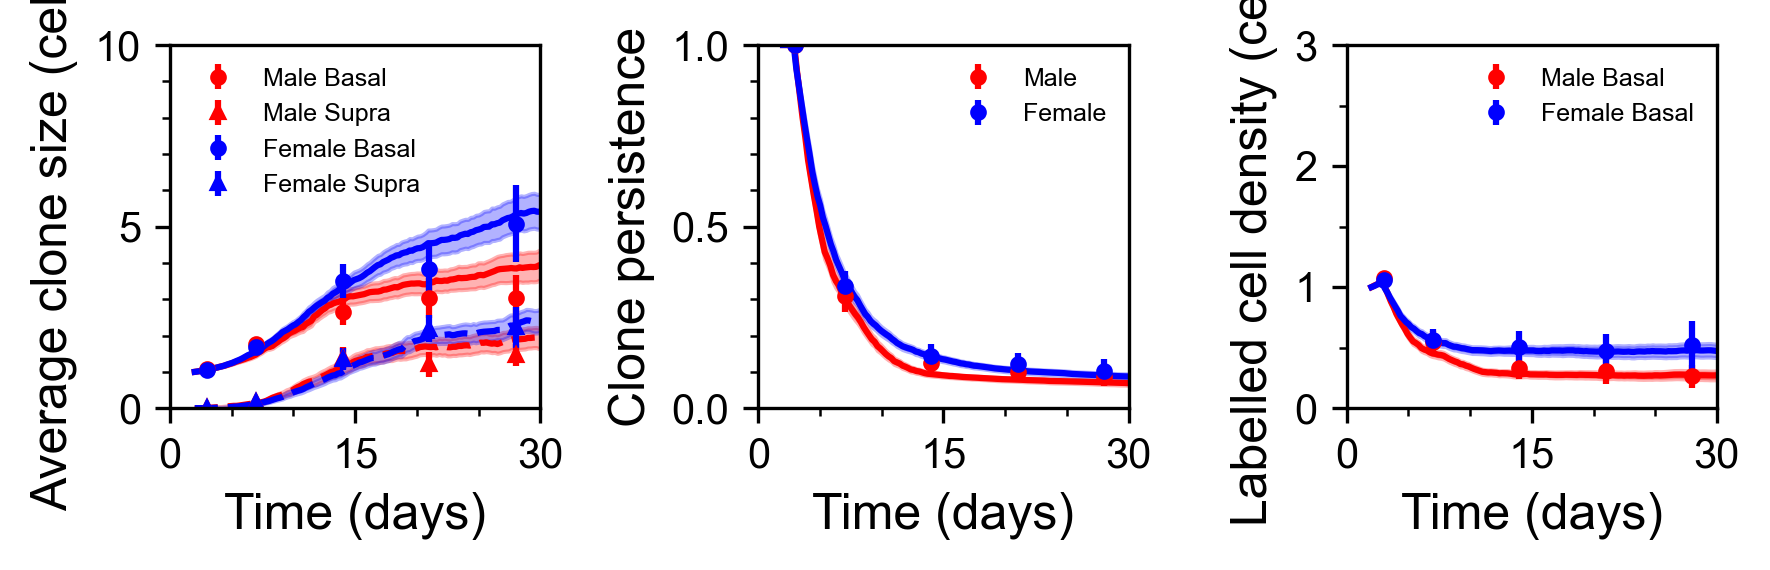

In [ ]:
pname = {'Notch1': 'notch', 'Lgr6': 'lgr6'}
fullsex = {'M': 'Male', 'F': 'Female'}
for promoter in ['Lgr6', 'Notch1']:
    nboots = 5000

    col = {'M': 'r', 'F': 'b'}
    conf = 0.68

    fig, axes = plt.subplots(1, 3, figsize=(6, 2), dpi=300)
    for sex in ['M', 'F']:
        if promoter == 'Notch1':
            exp_folder = 'experiment/notch/'
        elif promoter == 'lgr6':
            exp_folder = 'experiment/lgr6'
        else:
            assert(0)

        exp_data = load_object(exp_folder + f'data_{promoter}_{sex}.pkl')
        livesize = exp_data['livesize']
        # Subplot 1: Average Clone Size
        clone_anal = clones.xanalysis(livesize, verbose=False, tvals=exp_data['ctrTimeClonesize'])
        db = clone_anal.boot('av_bas_cs', nboots, None, sample_size=None)
        lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence=conf)
        axes[0].errorbar(clone_anal.tvals, clone_anal.av_bas_cs, upper68-lower68, fmt=f'{col[sex]}o', label=f'{fullsex[sex]} Basal')
        db = clone_anal.boot('av_sup_cs', nboots, None, sample_size=None)
        lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence=conf)
        axes[0].errorbar(clone_anal.tvals, clone_anal.av_sup_cs, upper68-lower68, fmt=f'{col[sex]}^', label=f'{fullsex[sex]} Supra')

        sim_data = sim_datasets_full[pname[promoter] + sex]
        sca = clones.lanalysis(sim_data.raw_data['liveCS']).sur_t0(sim_data.exp_times('basalCS')[0])
        xca = clones.xanalysis(exp_data['livesize']).sur_t0(0)
        sSlike = sca.S4like(sim_data.exp_times('basalCS')).sur_t0(sim_data.exp_times('basalCS')[0])
        sTlike = sca.CPlike(sim_data.exp_times('basalCS')).sur_t0(sim_data.exp_times('basalCS')[0])
        sDlike =  sca.Dlike(sim_data.exp_times('basalCS')).sur_t0(sim_data.exp_times('basalCS')[0])
        xSlike = xca.S4like()
        xTlike = xca.CPlike()
        xDlike = xca.Dlike()

        comb = clones.label_calc([sSlike, sTlike, sDlike], [xSlike.nclones, xTlike.nclones, xDlike.nclones], 'av_bas_cs', norm = True, sur = True)
        se = clones.boot_label_calc([sSlike, sTlike, sDlike], [xSlike.nclones, xTlike.nclones, xDlike.nclones], 'av_bas_cs', norm = True, nboots = 1000, sample_size=xca.nclones, sur = True)
        axes[0].plot(sim_data.tvec_by_quantity('basalCS'), comb, f'{col[sex]}-')
        axes[0].fill_between(sim_data.tvec_by_quantity('basalCS'), comb - se, comb + se, color = col[sex], alpha = 0.3)

        comb = clones.label_calc([sSlike, sTlike, sDlike], [xSlike.nclones, xTlike.nclones, xDlike.nclones], 'av_sup_cs', norm = True, sur = True)
        se = clones.boot_label_calc([sSlike, sTlike, sDlike], [xSlike.nclones, xTlike.nclones, xDlike.nclones], 'av_sup_cs', norm = True, nboots = 1000, sample_size=xca.nclones, sur = True)
        axes[0].plot(sim_data.tvec_by_quantity('supraCS'), comb, f'{col[sex]}--')
        axes[0].fill_between(sim_data.tvec_by_quantity('supraCS'), comb - se, comb + se, color = col[sex], alpha = 0.3)

    axes[0].set_xlabel('Time (days)')
    axes[0].set_ylabel('Average clone size (cells)')
    axes[0].legend(frameon=False, fontsize=6, loc='upper left')
    axes[0].set_ylim([0, 10])
    axes[0].set_yticks(np.arange(0, 11, 5))
    axes[0].set_yticks(np.arange(0, 11, 1), minor=True)
    axes[0].set_xlim([0, 30])
    axes[0].set_xticks(np.arange(0, 31, 15))
    axes[0].set_xticks(np.arange(0, 31, 5), minor=True)

    # Subplot 2: Labelled Cell Density
    for sex in ['M', 'F']:
        exp_data = load_object(exp_folder + f'data_{promoter}_{sex}.pkl')
        livesize = exp_data['livesize']
        clone_anal = clones.xanalysis(livesize, verbose=False, tvals=exp_data['ctrTimeClonesize'])
        db = clone_anal.boot('lcd', nboots, None, sample_size=None)
        lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence=conf)
        axes[2].errorbar(clone_anal.tvals, clone_anal.lcd, upper68-lower68, fmt=f'{col[sex]}o', label = f'{fullsex[sex]} Basal')
        db = clone_anal.boot('av_full_sup_cs', nboots, None, sample_size=None)
        lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence=conf)
        #axes[2].errorbar(clone_anal.tvals, clone_anal.av_full_sup_cs, upper68-lower68, fmt=f'{col[sex]}^--', label=f'{sex} Supra')    

        sim_data = sim_datasets_full[pname[promoter] + sex]
        sca = clones.lanalysis(sim_data.raw_data['liveCS']).sur_t0(sim_data.exp_times('basalCS')[0])
        xca = clones.xanalysis(exp_data['livesize']).sur_t0(0)
        sSlike = sca.S4like(sim_data.exp_times('basalCS')).sur_t0(sim_data.exp_times('basalCS')[0])
        sTlike = sca.CPlike(sim_data.exp_times('basalCS')).sur_t0(sim_data.exp_times('basalCS')[0])
        sDlike =  sca.Dlike(sim_data.exp_times('basalCS')).sur_t0(sim_data.exp_times('basalCS')[0])
        xSlike = xca.S4like()
        xTlike = xca.CPlike()
        xDlike = xca.Dlike()

        comb = clones.label_calc([sSlike, sTlike, sDlike], [xSlike.nclones, xTlike.nclones, xDlike.nclones], 'lcd', norm = True, sur = False)
        se = clones.boot_label_calc([sSlike, sTlike, sDlike], [xSlike.nclones, xTlike.nclones, xDlike.nclones], 'lcd', norm = True, nboots = 1000, sample_size=xca.nclones, sur = False)
        axes[2].plot(sim_data.tvec_by_quantity('basalCS'), comb, f'{col[sex]}-')
        axes[2].fill_between(sim_data.tvec_by_quantity('basalCS'), comb - se, comb + se, color = col[sex], alpha = 0.3)

    axes[2].set_xlabel('Time (days)')
    axes[2].set_ylabel('Labelled cell density (cells)')
    axes[2].legend(frameon=False, fontsize=6)
    axes[2].set_ylim([0, 3])
    axes[2].set_yticks(np.arange(0, 3.1, 1))
    axes[2].set_yticks(np.arange(0, 3.1, 0.5), minor=True)
    axes[2].set_xlim([0, 30])
    axes[2].set_xticks(np.arange(0, 31, 15))
    axes[2].set_xticks(np.arange(0, 31, 5), minor=True)

    # Subplot 3: Persistence
    for sex in ['M', 'F']:
        exp_data = load_object(exp_folder + f'data_{promoter}_{sex}.pkl')
        livesize = exp_data['livesize']
        clone_anal = clones.xanalysis(livesize, verbose=False, tvals=exp_data['ctrTimeClonesize'])
        db = clone_anal.boot('pers', nboots, None, sample_size=None)
        lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence=conf)
        axes[1].errorbar(clone_anal.tvals, clone_anal.pers, upper68-lower68, fmt=f'{col[sex]}o', label = f'{fullsex[sex]}')

        sim_data = sim_datasets_full[pname[promoter] + sex]
        sca = clones.lanalysis(sim_data.raw_data['liveCS']).sur_t0(sim_data.exp_times('basalCS')[0])
        xca = clones.xanalysis(exp_data['livesize']).sur_t0(0)
        sSlike = sca.S4like(sim_data.exp_times('basalCS')).sur_t0(sim_data.exp_times('basalCS')[0])
        sTlike = sca.CPlike(sim_data.exp_times('basalCS')).sur_t0(sim_data.exp_times('basalCS')[0])
        sDlike =  sca.Dlike(sim_data.exp_times('basalCS')).sur_t0(sim_data.exp_times('basalCS')[0])
        xSlike = xca.S4like()
        xTlike = xca.CPlike()
        xDlike = xca.Dlike()

        comb = clones.label_calc([sSlike, sTlike, sDlike], [xSlike.nclones, xTlike.nclones, xDlike.nclones], 'pers', norm = True, sur = False)
        se = clones.boot_label_calc([sSlike, sTlike, sDlike], [xSlike.nclones, xTlike.nclones, xDlike.nclones], 'pers', norm = True, nboots = 1000, sample_size=xca.nclones, sur = False)
        axes[1].plot(sim_data.tvec_by_quantity('basalCS'), comb, f'{col[sex]}-')
        axes[1].fill_between(sim_data.tvec_by_quantity('basalCS'), comb - se, comb + se, color = col[sex], alpha = 0.3)


    axes[1].set_xlabel('Time (days)')
    axes[1].set_ylabel('Clone persistence')
    axes[1].set_ylim([0, 1])
    axes[1].set_yticks(np.arange(0, 1.1, 0.5))
    axes[1].set_yticks(np.arange(0, 1.1, 0.1), minor=True)
    axes[1].set_xlim([0, 30])
    axes[1].set_xticks(np.arange(0, 31, 15))
    axes[1].set_xticks(np.arange(0, 31, 5), minor=True)
    axes[1].legend(frameon=False, fontsize=6, loc='upper right')

    plt.tight_layout()
    plt.savefig(f'Figures/{figfolder}F5_with_model_{promoter}_M_F_av.pdf')
    plt.show()
